In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras import layers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import backend as K

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve, average_precision_score,
    precision_recall_curve
)

# Optuna
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Reproducibilité
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f" TensorFlow : {tf.__version__}")
print(f" Optuna     : {optuna.__version__}")
print(f" GPU dispo  : {len(tf.config.list_physical_devices('GPU')) > 0}")

2026-04-30 20:32:23.508111: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777581143.711310      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777581143.788144      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777581144.210083      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777581144.210127      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777581144.210130      57 computation_placer.cc:177] computation placer alr

 TensorFlow : 2.19.0
 Optuna     : 4.8.0
 GPU dispo  : True


In [3]:
df = pd.read_csv('/kaggle/input/datasets/organizations/mlg-ulb/creditcardfraud/creditcard.csv')
print(f"Shape : {df.shape}")
print(f"Fraudes : {df['Class'].sum()} ({df['Class'].mean()*100:.3f}%)")
df.head()

Shape : (284807, 31)
Fraudes : 492 (0.173%)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
print("=== Info générales ===")
df.info()
print("\n=== Valeurs manquantes ===")
print(df.isnull().sum().sum(), "valeurs manquantes")

=== Info générales ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  

Distribution des classes :
Class
0    284315
1       492
Name: count, dtype: int64

Taux de fraude : 0.173%


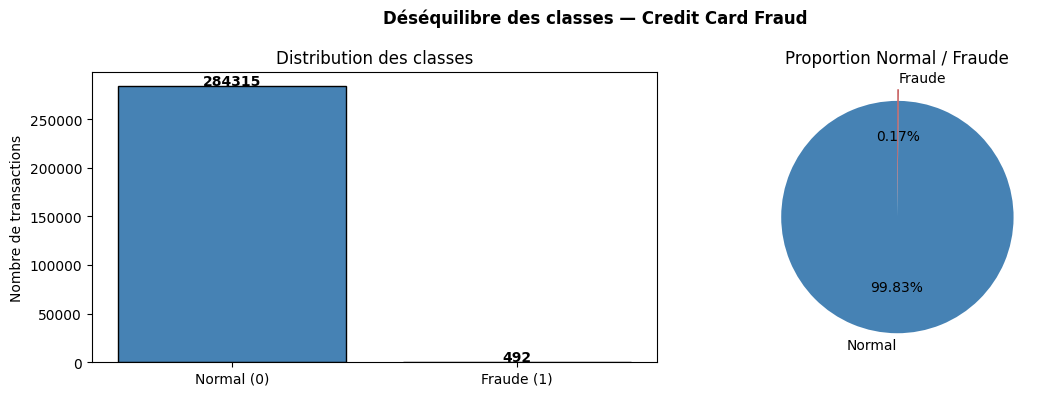

In [5]:
# Distribution des classes
class_counts = df['Class'].value_counts()
print("Distribution des classes :")
print(class_counts)
print(f"\nTaux de fraude : {class_counts[1]/len(df)*100:.3f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar plot
axes[0].bar(['Normal (0)', 'Fraude (1)'], class_counts.values,
            color=['steelblue', 'firebrick'], edgecolor='black')
axes[0].set_title('Distribution des classes')
axes[0].set_ylabel('Nombre de transactions')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 500, str(v), ha='center', fontweight='bold')

# Pie chart
axes[1].pie(class_counts.values, labels=['Normal', 'Fraude'],
            colors=['steelblue', 'firebrick'], autopct='%1.2f%%',
            startangle=90, explode=(0, 0.1))
axes[1].set_title('Proportion Normal / Fraude')

plt.suptitle('Déséquilibre des classes — Credit Card Fraud', fontweight='bold')
plt.tight_layout()
plt.show()

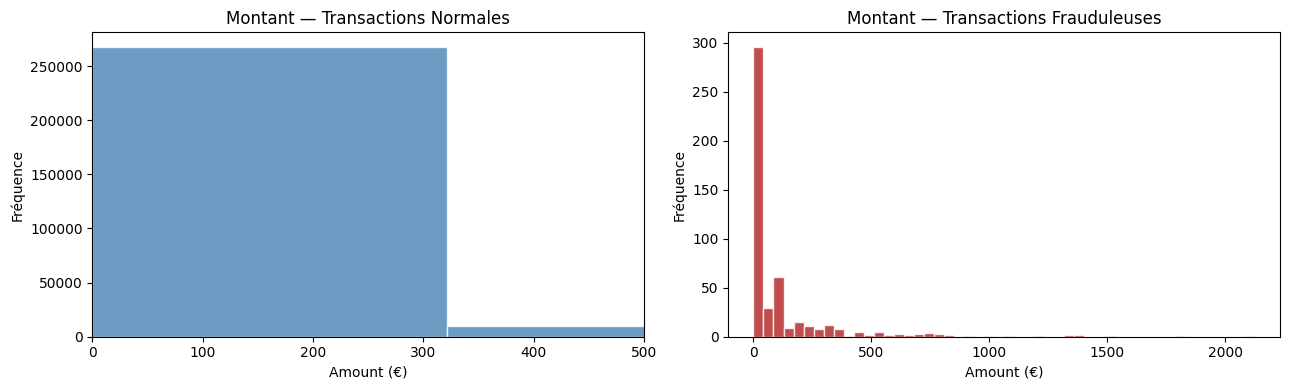

Montant moyen — Normal : 88.29€
Montant moyen — Fraude : 122.21€


In [6]:
# Distribution du montant des transactions par classe
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

normal_amount = df[df['Class'] == 0]['Amount']
fraud_amount  = df[df['Class'] == 1]['Amount']

axes[0].hist(normal_amount, bins=80, color='steelblue', alpha=0.8, edgecolor='white')
axes[0].set_title('Montant — Transactions Normales')
axes[0].set_xlabel('Amount (€)')
axes[0].set_ylabel('Fréquence')
axes[0].set_xlim(0, 500)

axes[1].hist(fraud_amount, bins=50, color='firebrick', alpha=0.8, edgecolor='white')
axes[1].set_title('Montant — Transactions Frauduleuses')
axes[1].set_xlabel('Amount (€)')
axes[1].set_ylabel('Fréquence')

plt.tight_layout()
plt.show()

print(f"Montant moyen — Normal : {normal_amount.mean():.2f}€")
print(f"Montant moyen — Fraude : {fraud_amount.mean():.2f}€")

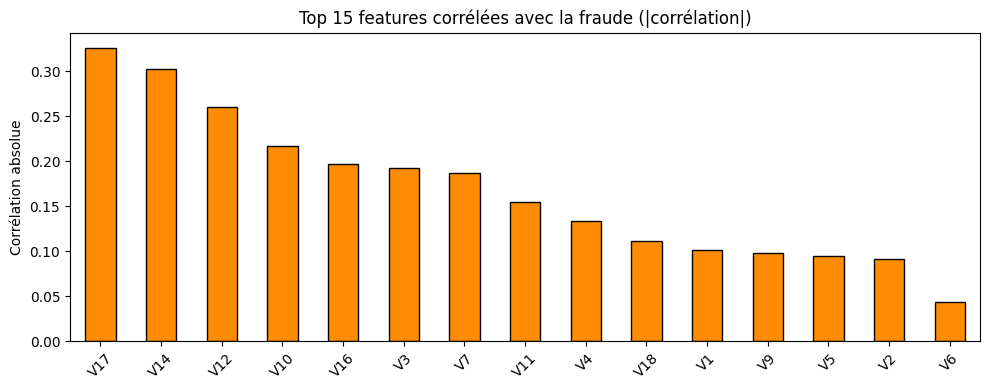

In [7]:
# Corrélation des features avec la classe
corr_with_class = df.corr()['Class'].drop('Class').abs().sort_values(ascending=False)

plt.figure(figsize=(10, 4))
corr_with_class.head(15).plot(kind='bar', color='darkorange', edgecolor='black')
plt.title('Top 15 features corrélées avec la fraude (|corrélation|)')
plt.ylabel('Corrélation absolue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
# 1. DROP TIME 
df = df.drop('Time', axis=1)

# 2. Split AVANT scaling (anti leakage)
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)


# 3. Scaling uniquement Amount
scaler = StandardScaler()

X_train['Amount_scaled'] = scaler.fit_transform(X_train[['Amount']])
X_test['Amount_scaled']  = scaler.transform(X_test[['Amount']])

X_train = X_train.drop('Amount', axis=1)
X_test = X_test.drop('Amount', axis=1)
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train
)
X_train_normal = X_train[y_train == 0]
X_val_normal   = X_val[y_val == 0]
X_test_normal  = X_test[y_test == 0]

X_train_normal_tf = tf.cast(X_train_normal, tf.float32)
X_val_tf          = tf.cast(X_val, tf.float32)
X_test_tf         = tf.cast(X_test, tf.float32)


In [9]:
print(f"\nNormal train : {X_train_normal.shape}")
print(f"Normal test  : {X_test_normal.shape}")
print(f"Fraude test  : {X_test_fraud.shape}")


Normal train : (227451, 29)
Normal test  : (56864, 29)
Fraude test  : (98, 29)


In [12]:
features = df.drop(columns=['Class'])
labels   = df['Class'].values

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(features)

INPUT_DIM = X_scaled.shape[1]

In [13]:
def get_threshold_from_pr(reconstruction_errors_train, percentile=95):
    """Seuil basé sur le percentile des erreurs de reconstruction sur le train."""
    return np.percentile(reconstruction_errors_train, percentile)


def evaluate_model(name, rec_errors_test, rec_errors_train, y_test,
                   percentile=95, verbose=True):
    """
    Évalue un autoencodeur à partir de ses erreurs de reconstruction.
    Retourne un dict de métriques.
    """
    threshold = get_threshold_from_pr(rec_errors_train, percentile)
    y_pred    = (rec_errors_test > threshold).astype(int)

    # Métriques
    auc_roc   = roc_auc_score(y_test, rec_errors_test)
    auc_pr    = average_precision_score(y_test, rec_errors_test)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall    = recall_score(y_test, y_pred, zero_division=0)
    f1        = f1_score(y_test, y_pred, zero_division=0)

    if verbose:
        print(f"\n{'='*55}")
        print(f"  {name}")
        print(f"{'='*55}")
        print(f"  Seuil (percentile {percentile}) : {threshold:.6f}")
        print(f"  AUC-ROC          : {auc_roc:.4f}")
        print(f"  AUC-PR           : {auc_pr:.4f}")
        print(f"  Précision        : {precision:.4f}")
        print(f"  Rappel           : {recall:.4f}")
        print(f"  F1-Score         : {f1:.4f}")
        print(classification_report(y_test, y_pred,
                                    target_names=['Normal', 'Fraude'],
                                    zero_division=0))

    return {
        'name': name,
        'threshold': threshold,
        'auc_roc': auc_roc,
        'auc_pr': auc_pr,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'y_pred': y_pred,
        'rec_errors': rec_errors_test
    }


def plot_reconstruction_errors(results_list, y_test, title_suffix=""):
    """Histogrammes des erreurs de reconstruction pour chaque modèle."""
    n = len(results_list)
    fig, axes = plt.subplots(1, n, figsize=(6*n, 4))
    if n == 1:
        axes = [axes]

    for ax, res in zip(axes, results_list):
        errors = res['rec_errors']
        ax.hist(errors[y_test == 0], bins=60, alpha=0.6,
                color='steelblue', label='Normal', density=True)
        ax.hist(errors[y_test == 1], bins=60, alpha=0.7,
                color='tomato', label='Fraude', density=True)
        ax.axvline(res['threshold'], color='black', linestyle='--',
                   linewidth=1.5, label=f"Seuil={res['threshold']:.4f}")
        ax.set_title(res['name'], fontsize=12)
        ax.set_xlabel('Erreur de reconstruction')
        ax.set_ylabel('Densité')
        ax.legend(fontsize=8)

    plt.suptitle(f'Distribution des erreurs de reconstruction {title_suffix}',
                 fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()


def plot_roc_pr_curves(results_list, y_test):
    """Courbes ROC et PR côte à côte."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    colors = ['steelblue', 'tomato', 'forestgreen', 'darkorange']

    for res, color in zip(results_list, colors):
        # ROC
        fpr, tpr, _ = roc_curve(y_test, res['rec_errors'])
        ax1.plot(fpr, tpr, color=color, lw=2,
                 label=f"{res['name']} (AUC={res['auc_roc']:.4f})")
        # PR
        prec, rec, _ = precision_recall_curve(y_test, res['rec_errors'])
        ax2.plot(rec, prec, color=color, lw=2,
                 label=f"{res['name']} (AP={res['auc_pr']:.4f})")

    ax1.plot([0,1],[0,1],'k--', lw=1)
    ax1.set_xlabel('Taux Faux Positifs')
    ax1.set_ylabel('Taux Vrais Positifs')
    ax1.set_title('Courbe ROC')
    ax1.legend(loc='lower right', fontsize=9)
    ax1.grid(alpha=0.3)

    ax2.set_xlabel('Rappel')
    ax2.set_ylabel('Précision')
    ax2.set_title('Courbe Precision-Recall')
    ax2.legend(loc='upper right', fontsize=9)
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


def plot_comparison_bar(results_list):
    """Barres comparatives AUC-ROC / F1 / Rappel."""
    names    = [r['name'] for r in results_list]
    metrics  = ['auc_roc', 'auc_pr', 'f1', 'recall', 'precision']
    labels   = ['AUC-ROC', 'AUC-PR', 'F1', 'Rappel', 'Précision']
    x = np.arange(len(metrics))
    width = 0.22
    colors = ['#4878CF','#D65F5F','#6ACC65','#B47CC7']

    fig, ax = plt.subplots(figsize=(12, 5))
    for i, (res, color) in enumerate(zip(results_list, colors)):
        vals = [res[m] for m in metrics]
        offset = (i - len(results_list)/2 + 0.5) * width
        bars = ax.bar(x + offset, vals, width, label=res['name'], color=color, alpha=0.85)
        for bar in bars:
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + 0.005,
                    f"{bar.get_height():.3f}",
                    ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=11)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel('Score')
    ax.set_title('Comparaison des autoencodeurs — métriques clés', fontsize=13)
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()


print("Fonctions utilitaires chargées.")

Fonctions utilitaires chargées.


In [29]:
# ── Architecture Dense AE ─────────────────────────────────────────────
def build_dense_ae(input_dim,
                   encoding_dim=14,
                   hidden_dims=[32],
                   dropout_rate=0.1,
                   learning_rate=1e-3):

    inp = layers.Input(shape=(input_dim,))

    # Encoder
    x = inp
    for h in hidden_dims:
        x = layers.Dense(h, activation='relu')(x)
        x = layers.Dropout(dropout_rate)(x)

    encoded = layers.Dense(encoding_dim, activation='relu')(x)

    # Decoder
    x = encoded
    for h in reversed(hidden_dims):
        x = layers.Dense(h, activation='relu')(x)
        x = layers.Dropout(dropout_rate)(x)

    decoded = layers.Dense(input_dim, activation='linear')(x)

    model = Model(inp, decoded, name='DenseAE')
    model.compile(optimizer=Adam(learning_rate), loss='mse')

    return model


# ── Conversion TensorFlow ─────────────────────────────────────────────
X_train_normal_tf = tf.cast(X_train_normal, tf.float32)
X_val_normal_tf   = tf.cast(X_val_normal, tf.float32)
X_val_tf          = tf.cast(X_val, tf.float32)
X_test_tf         = tf.cast(X_test, tf.float32)


# ── Entraînement ──────────────────────────────────────────────────────
print("Entraînement Dense AE...")

dense_ae = build_dense_ae(INPUT_DIM)
dense_ae.summary()

es = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

hist_dense = dense_ae.fit(
    X_train_normal_tf, X_train_normal_tf,
    epochs=100,
    batch_size=256,
    validation_data=(X_val_normal_tf, X_val_normal_tf),  # ✅ seulement normal
    callbacks=[es],
    verbose=1
)


# ── Reconstruction ────────────────────────────────────────────────────
recon_val  = dense_ae.predict(X_val_tf,  verbose=0)
recon_test = dense_ae.predict(X_test_tf, verbose=0)

# erreurs MSE
err_val  = np.mean((recon_val  - X_val_tf.numpy())**2, axis=1)
err_test = np.mean((recon_test - X_test_tf.numpy())**2, axis=1)


# ── Évaluation (avec ta fonction existante) ───────────────────────────
results_dense = evaluate_model(
    name='Dense AE',
    rec_errors_test=err_test,
    rec_errors_train=err_val[y_val == 0],  # seulement normal pour seuil
    y_test=y_test,
    percentile=95
)

Entraînement Dense AE...


Model: "DenseAE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 32)             │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 14)             │           462 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 32)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 29)             │           957 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,859 (11.17 KB)

 Trainable params: 2,859 (11.17 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.7580 - val_loss: 0.2974
Epoch 2/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3613 - val_loss: 0.2214
Epoch 3/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3095 - val_loss: 0.1948
Epoch 4/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2892 - val_loss: 0.1767
Epoch 5/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2784 - val_loss: 0.1660
Epoch 6/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2688 - val_loss: 0.1583
Epoch 7/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2618 - val_loss: 0.1481
Epoch 8/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2562 - val_loss: 0.1466
Epoch 9/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2518 - val_loss: 0.1367
Epoch 10/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2499 - val_loss: 0.1346
Epoch 11/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2429 - val_loss: 0.1291
Epoch 12/100
711/711 ━━━━━━━━━━━━━━━━━━━━

In [30]:
# ── Bruit gaussien ───────────────────────────────────────────────────
def add_gaussian_noise(X, noise_factor=0.1):
    noise = noise_factor * np.random.randn(*X.shape)
    return X + noise


# ── Architecture Denoising AE ────────────────────────────────────────
def build_denoising_ae(input_dim,
                       encoding_dim=14,
                       hidden_dims=[32],
                       dropout_rate=0.1,
                       learning_rate=1e-3):

    inp = layers.Input(shape=(input_dim,))

    # Encoder
    x = inp
    for h in hidden_dims:
        x = layers.Dense(h, activation='relu')(x)
        x = layers.Dropout(dropout_rate)(x)

    encoded = layers.Dense(encoding_dim, activation='relu')(x)

    # Decoder
    x = encoded
    for h in reversed(hidden_dims):
        x = layers.Dense(h, activation='relu')(x)
        x = layers.Dropout(dropout_rate)(x)

    decoded = layers.Dense(input_dim, activation='linear')(x)

    model = Model(inp, decoded, name='DenoisingAE')
    model.compile(optimizer=Adam(learning_rate), loss='mse')

    return model


# ── Conversion numpy (IMPORTANT pour bruit) ──────────────────────────
X_train_normal_np = X_train_normal.values
X_val_normal_np   = X_val_normal.values
X_val_np          = X_val.values
X_test_np         = X_test.values


# ── Ajout de bruit ───────────────────────────────────────────────────
NOISE_FACTOR = 0.15

X_train_noisy = add_gaussian_noise(X_train_normal_np, NOISE_FACTOR)
X_val_noisy   = add_gaussian_noise(X_val_normal_np,   NOISE_FACTOR)


# ── Entraînement ─────────────────────────────────────────────────────
print(f"Entraînement Denoising AE (noise={NOISE_FACTOR})...")

denoising_ae = build_denoising_ae(INPUT_DIM)
denoising_ae.summary()

es = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

hist_denoising = denoising_ae.fit(
    X_train_noisy, X_train_normal_np,  # ✅ bruit → propre
    epochs=100,
    batch_size=256,
    validation_data=(X_val_noisy, X_val_normal_np),  # ✅ seulement normal
    callbacks=[es],
    verbose=1
)


# ── Reconstruction ───────────────────────────────────────────────────
recon_val  = denoising_ae.predict(X_val_np,  verbose=0)
recon_test = denoising_ae.predict(X_test_np, verbose=0)

# erreurs MSE
err_val  = np.mean((recon_val  - X_val_np)**2, axis=1)
err_test = np.mean((recon_test - X_test_np)**2, axis=1)


# ── Évaluation (propre) ──────────────────────────────────────────────
results_denoising = evaluate_model(
    name='Denoising AE',
    rec_errors_test=err_test,
    rec_errors_train=err_val[y_val == 0],  # ✅ uniquement normal
    y_test=y_test,
    percentile=95
)

Entraînement Denoising AE (noise=0.15)...


Model: "DenoisingAE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 32)             │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 14)             │           462 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 32)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 29)             │           957 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,859 (11.17 KB)

 Trainable params: 2,859 (11.17 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.7538 - val_loss: 0.3098
Epoch 2/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3706 - val_loss: 0.2422
Epoch 3/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3254 - val_loss: 0.2119
Epoch 4/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3050 - val_loss: 0.1986
Epoch 5/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2935 - val_loss: 0.1914
Epoch 6/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2869 - val_loss: 0.1826
Epoch 7/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2784 - val_loss: 0.1717
Epoch 8/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2698 - val_loss: 0.1665
Epoch 9/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2677 - val_loss: 0.1667
Epoch 10/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2664 - val_loss: 0.1615
Epoch 11/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2627 - val_loss: 0.1572
Epoch 12/100
711/711 ━━━━━━━━━━━━━━━━━━━━

In [21]:
# 1. Imports
from tensorflow.keras import layers, Model
from tensorflow.keras.optimizers import Adam
import tensorflow as tf
import numpy as np

# 2. Sampling
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# 3. VAE
class VAE(Model):
    def __init__(self, input_dim, latent_dim=10,
                 hidden_dims=[64, 32], dropout_rate=0.1, beta=0.5):
        super().__init__()
        self.beta = beta

        # Encoder
        enc_input = layers.Input(shape=(input_dim,))
        x = enc_input
        for h in hidden_dims:
            x = layers.Dense(h, activation='relu')(x)
        z_mean = layers.Dense(latent_dim)(x)
        z_log_var = layers.Dense(latent_dim)(x)
        z = Sampling()([z_mean, z_log_var])

        self.encoder = Model(enc_input, [z_mean, z_log_var, z])

        # Decoder
        dec_input = layers.Input(shape=(latent_dim,))
        x = dec_input
        for h in reversed(hidden_dims):
            x = layers.Dense(h, activation='relu')(x)
        dec_output = layers.Dense(input_dim)(x)

        self.decoder = Model(dec_input, dec_output)

    def call(self, x):
        z_mean, z_log_var, z = self.encoder(x)
        reconstruction = self.decoder(z)

        rec_loss = tf.reduce_mean(tf.square(x - reconstruction))
        kl_loss = -0.5 * tf.reduce_mean(
            1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)
        )

        self.add_loss(rec_loss + self.beta * kl_loss)
        return reconstruction

    def reconstruction_error(self, X):
        z_mean, z_log_var, z = self.encoder(X)
        X_hat = self.decoder(z)
        return np.mean((X - X_hat.numpy())**2, axis=1)

In [26]:
# ── Conversion numpy (IMPORTANT) ─────────────────────────────────────
X_train_normal_np = X_train_normal.values
X_val_normal_np   = X_val_normal.values
X_val_np          = X_val.values
X_test_np         = X_test.values


# ── Entraînement VAE ─────────────────────────────────────────────────
print("Entraînement VAE...")

vae = VAE(
    input_dim=INPUT_DIM,
    latent_dim=10,
    hidden_dims=[64, 32],
    dropout_rate=0.1,
    beta=0.5
)

vae.compile(optimizer=Adam(1e-3))

vae.compile(optimizer=Adam(1e-3))

vae.encoder.summary()
vae.decoder.summary()

es = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

hist_vae = vae.fit(
    X_train_normal_np, X_train_normal_np,   # ✅ seulement normal
    epochs=100,
    batch_size=256,
    validation_data=(X_val_normal_np, X_val_normal_np),  # ✅ seulement normal
    callbacks=[es],
    verbose=1
)


# ── Reconstruction ───────────────────────────────────────────────────
rec_val_vae  = vae.reconstruction_error(X_val_np)
rec_test_vae = vae.reconstruction_error(X_test_np)


# ── Évaluation (propre) ──────────────────────────────────────────────
results_vae = evaluate_model(
    name='VAE',
    rec_errors_test=rec_test_vae,
    rec_errors_train=rec_val_vae[y_val == 0],  # ✅ seuil sur validation normal
    y_test=y_test,
    percentile=95
)

Entraînement VAE...


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None, 29)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_27 (Dense)    │ (None, 64)        │      1,920 │ input_layer_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_28 (Dense)    │ (None, 32)        │      2,080 │ dense_27[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_29 (Dense)    │ (None, 10)        │        330 │ dense_28[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_30 (Dense)    │ (None, 10)        │        330 │ dense_28[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling_1          │ (None, 10)        │          0 │ dense_29[0][0],   │
│ (Sampling)          │                   │            │ dense_30[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,660 (18.20 KB)

 Trainable params: 4,660 (18.20 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

 Total params: 4,349 (16.99 KB)

 Trainable params: 4,349 (16.99 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - loss: 1.0205 - val_loss: 0.8112
Epoch 2/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.7608 - val_loss: 0.7062
Epoch 3/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6803 - val_loss: 0.6658
Epoch 4/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6503 - val_loss: 0.6465
Epoch 5/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6351 - val_loss: 0.6357
Epoch 6/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6261 - val_loss: 0.6269
Epoch 7/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6197 - val_loss: 0.6223
Epoch 8/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6150 - val_loss: 0.6162
Epoch 9/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6117 - val_loss: 0.6150
Epoch 10/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6082 - val_loss: 0.6138
Epoch 11/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6052 - val_loss: 0.6081
Epoch 12/100
711/711 ━━━━━━━━━━━━━━━━━━━━

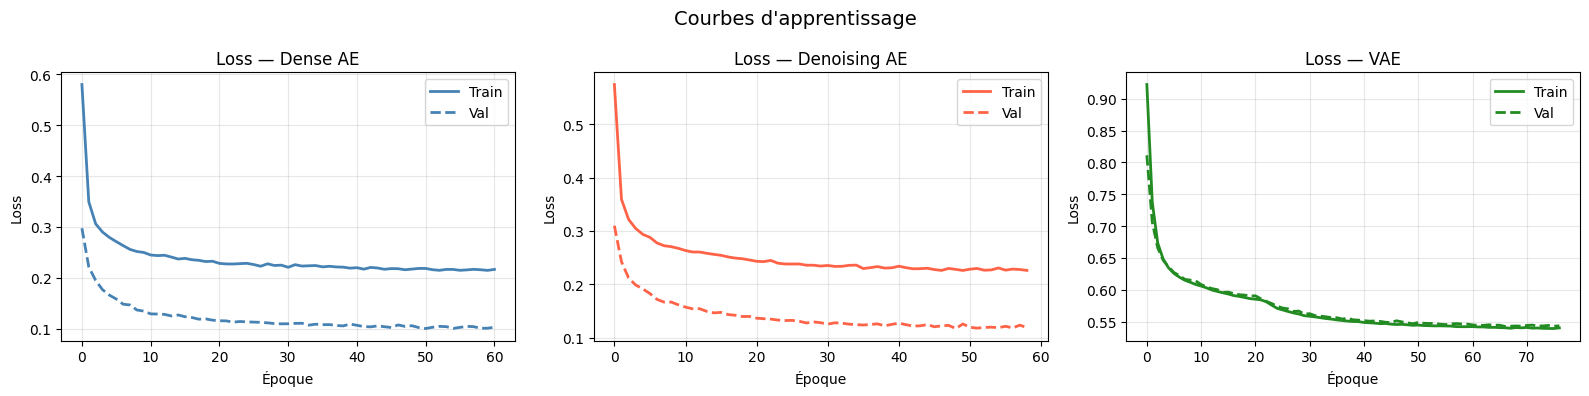

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

histories = [
    ('Dense AE', hist_dense, 'steelblue'),
    ('Denoising AE', hist_denoising, 'tomato'),
    ('VAE', hist_vae, 'forestgreen')
]

for ax, (name, hist, color) in zip(axes, histories):
    ax.plot(hist.history['loss'], color=color, lw=2, label='Train')

    if 'val_loss' in hist.history:
        ax.plot(hist.history['val_loss'],
                color=color, lw=2, linestyle='--', label='Val')

    ax.set_title(f'Loss — {name}', fontsize=12)
    ax.set_xlabel('Époque')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Courbes d'apprentissage", fontsize=14)
plt.tight_layout()
plt.show()

In [33]:
all_results = [results_dense, results_denoising, results_vae]

# ── Tableau récapitulatif ──────────────────────────────────────────────────────
metrics_df = pd.DataFrame([{
    'Modèle'    : r['name'],
    'AUC-ROC'   : round(r['auc_roc'],   4),
    'AUC-PR'    : round(r['auc_pr'],    4),
    'F1-Score'  : round(r['f1'],        4),
    'Rappel'    : round(r['recall'],    4),
    'Précision' : round(r['precision'], 4),
} for r in all_results])

print("\n" + "="*65)
print("         RÉSULTATS COMPARATIFS — SANS OPTUNA")
print("="*65)
print(metrics_df.to_string(index=False))
print()

# Identifier le meilleur modèle sur F1-Score
best_idx   = metrics_df['F1-Score'].idxmax()
best_model = metrics_df.loc[best_idx, 'Modèle']
print(f">>> Meilleur modèle (F1) : {best_model} <<<")


         RÉSULTATS COMPARATIFS — SANS OPTUNA
      Modèle  AUC-ROC  AUC-PR  F1-Score  Rappel  Précision
    Dense AE   0.9475  0.6041    0.0560  0.8571     0.0289
Denoising AE   0.9624  0.5803    0.0571  0.8571     0.0295
         VAE   0.9399  0.4972    0.0534  0.8061     0.0276

>>> Meilleur modèle (F1) : Denoising AE <<<


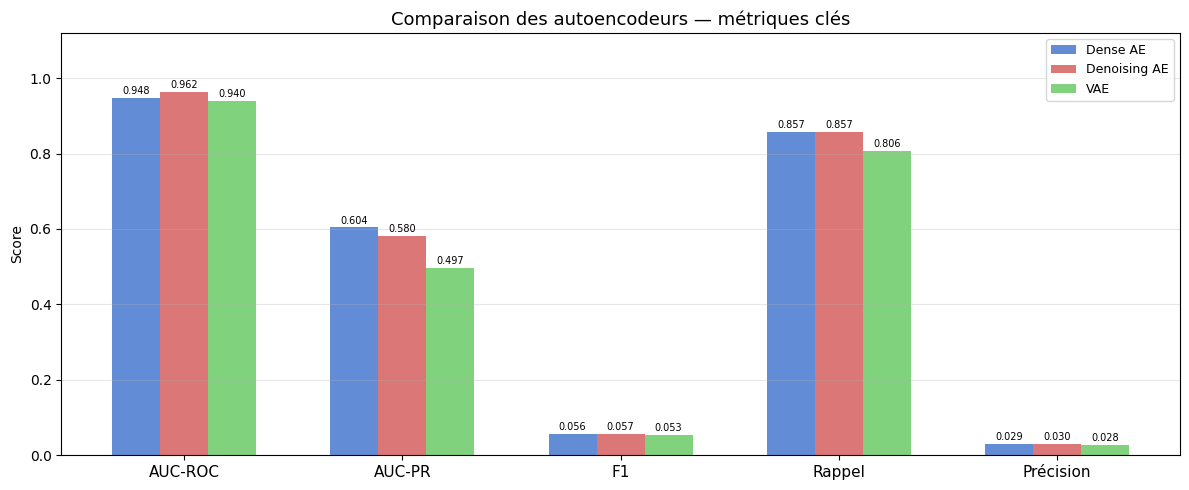

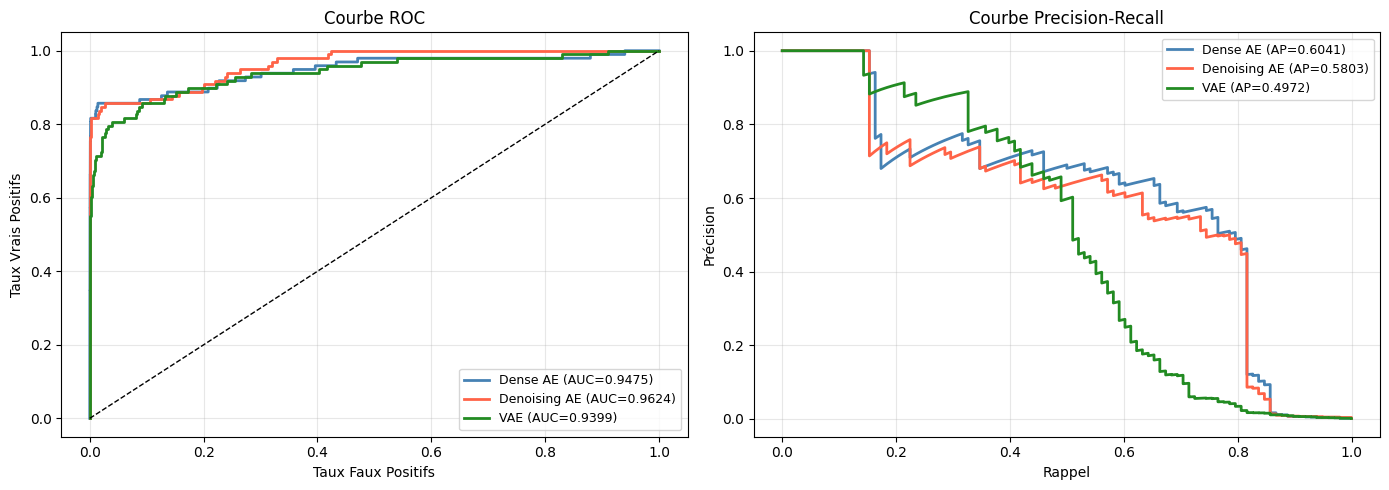

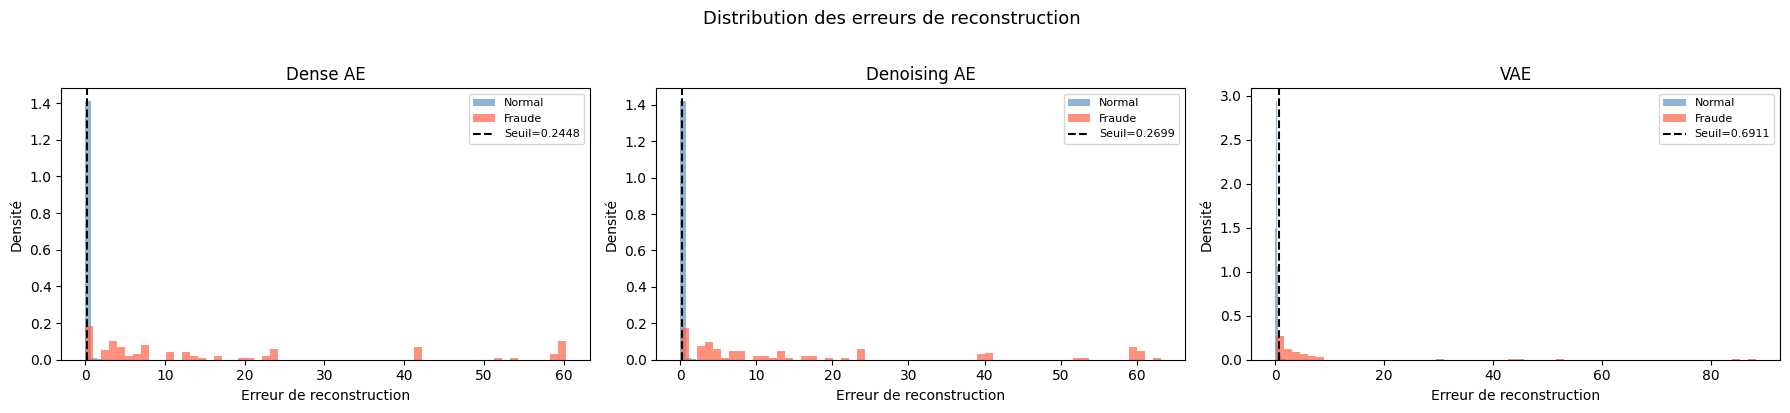

In [34]:
# ── Visualisations comparatives ────────────────────────────────────────────────
plot_comparison_bar(all_results)
plot_roc_pr_curves(all_results, y_test)
plot_reconstruction_errors(all_results, y_test)

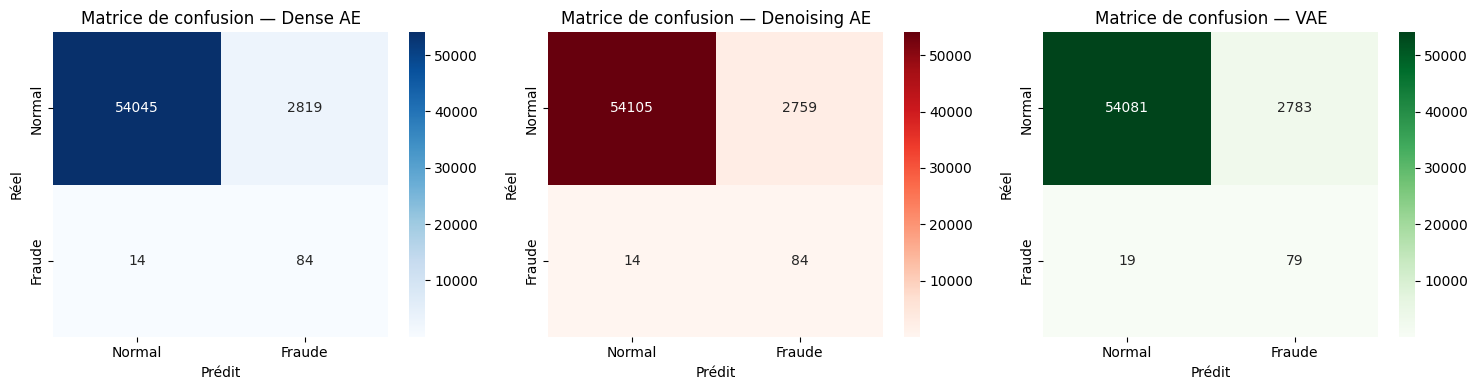

In [35]:
# ── Matrices de confusion côte à côte ─────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, res, color in zip(axes, all_results,
                          ['Blues', 'Reds', 'Greens']):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap=color, ax=ax,
                xticklabels=['Normal','Fraude'],
                yticklabels=['Normal','Fraude'])
    ax.set_title(f"Matrice de confusion — {res['name']}")
    ax.set_xlabel('Prédit')
    ax.set_ylabel('Réel')

plt.tight_layout()
plt.show()

In [36]:
print(f"Modèle sélectionné pour Optuna : {best_model}")
print("Lancement de l'optimisation Optuna (50 trials)...")

N_TRIALS   = 50
N_EPOCHS   = 80   # budget réduit pour accélérer les trials
BATCH_SIZE = 256

Modèle sélectionné pour Optuna : Denoising AE
Lancement de l'optimisation Optuna (50 trials)...


In [37]:
# ════════════════════════════════════════════════════════════════════════════════
# OPTUNA — VAE
# ════════════════════════════════════════════════════════════════════════════════

def build_vae_optuna(trial, input_dim):
    latent_dim   = trial.suggest_int('latent_dim', 4, 20)
    n_layers     = trial.suggest_int('n_layers', 1, 3)
    hidden_dims  = [trial.suggest_int(f'units_l{i}', 16, 128, step=16)
                    for i in range(n_layers)]
    dropout_rate = trial.suggest_float('dropout_rate', 0.0, 0.4)
    beta         = trial.suggest_float('beta', 0.01, 2.0, log=True)
    lr           = trial.suggest_float('lr', 1e-4, 1e-2, log=True)

    model = VAE(input_dim, latent_dim=latent_dim, hidden_dims=hidden_dims,
                dropout_rate=dropout_rate, beta=beta, name='VAE_optuna')
    model.compile(optimizer=Adam(lr))
    return model


def objective_vae(trial):
    K.clear_session()
    model = build_vae_optuna(trial, INPUT_DIM)
    es    = EarlyStopping(monitor='val_loss', patience=7,
                          restore_best_weights=True, verbose=0)
    model.fit(X_train, X_train,
              epochs=N_EPOCHS, batch_size=BATCH_SIZE,
              validation_data=(X_val, X_val),
              callbacks=[es], verbose=0)

    rec_train = model.reconstruction_error(X_train)
    rec_test  = model.reconstruction_error(X_test)
    threshold = get_threshold_from_pr(rec_train, percentile=95)
    y_pred    = (rec_test > threshold).astype(int)
    return f1_score(y_test, y_pred, zero_division=0)


# ════════════════════════════════════════════════════════════════════════════════
# OPTUNA — Denoising AE
# ════════════════════════════════════════════════════════════════════════════════

def build_denoising_ae_optuna(trial, input_dim):
    encoding_dim = trial.suggest_int('encoding_dim', 4, 24)
    n_layers     = trial.suggest_int('n_layers', 1, 3)
    hidden_dims  = [trial.suggest_int(f'units_l{i}', 16, 128, step=16)
                    for i in range(n_layers)]
    dropout_rate = trial.suggest_float('dropout_rate', 0.0, 0.4)
    noise_factor = trial.suggest_float('noise_factor', 0.05, 0.4)
    lr           = trial.suggest_float('lr', 1e-4, 1e-2, log=True)

    trial.set_user_attr('noise_factor', noise_factor)
    model = build_denoising_ae(input_dim, encoding_dim=encoding_dim,
                               hidden_dims=hidden_dims,
                               dropout_rate=dropout_rate,
                               learning_rate=lr)
    return model, noise_factor


def objective_denoising(trial):
    K.clear_session()
    model, nf = build_denoising_ae_optuna(trial, INPUT_DIM)
    X_tr_noisy = add_gaussian_noise(X_train, nf)
    X_v_noisy  = add_gaussian_noise(X_val,   nf)
    es = EarlyStopping(monitor='val_loss', patience=7,
                       restore_best_weights=True, verbose=0)
    model.fit(X_tr_noisy, X_train,
              epochs=N_EPOCHS, batch_size=BATCH_SIZE,
              validation_data=(X_v_noisy, X_val),
              callbacks=[es], verbose=0)

    rec_train = np.mean((model.predict(X_tr_noisy, verbose=0) - X_train)**2, axis=1)
    rec_test  = np.mean((model.predict(X_test,     verbose=0) - X_test )**2, axis=1)
    threshold = get_threshold_from_pr(rec_train, percentile=95)
    y_pred    = (rec_test > threshold).astype(int)
    return f1_score(y_test, y_pred, zero_division=0)


# ── Lancement de l'étude ───────────────────────────────────────────────────────
if best_model == 'VAE':
    study = optuna.create_study(direction='maximize',
                                study_name='VAE_fraud',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective_vae, n_trials=N_TRIALS, show_progress_bar=True)
elif best_model == 'Denoising AE':
    study = optuna.create_study(direction='maximize',
                                study_name='DenoisingAE_fraud',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective_denoising, n_trials=N_TRIALS, show_progress_bar=True)
else:
    # Fallback Dense AE (si Dense AE était le meilleur)
    def build_dense_ae_optuna(trial, input_dim):
        encoding_dim = trial.suggest_int('encoding_dim', 4, 24)
        n_layers     = trial.suggest_int('n_layers', 1, 3)
        hidden_dims  = [trial.suggest_int(f'units_l{i}', 16, 128, step=16)
                        for i in range(n_layers)]
        dropout_rate = trial.suggest_float('dropout_rate', 0.0, 0.4)
        lr           = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
        return build_dense_ae(input_dim, encoding_dim, hidden_dims, dropout_rate, lr)

    def objective_dense(trial):
        K.clear_session()
        model = build_dense_ae_optuna(trial, INPUT_DIM)
        es = EarlyStopping(monitor='val_loss', patience=7,
                           restore_best_weights=True, verbose=0)
        model.fit(X_train, X_train, epochs=N_EPOCHS, batch_size=BATCH_SIZE,
                  validation_data=(X_val, X_val), callbacks=[es], verbose=0)
        rec_train = np.mean((model.predict(X_train, verbose=0) - X_train)**2, axis=1)
        rec_test  = np.mean((model.predict(X_test,  verbose=0) - X_test )**2, axis=1)
        threshold = get_threshold_from_pr(rec_train, percentile=95)
        y_pred    = (rec_test > threshold).astype(int)
        return f1_score(y_test, y_pred, zero_division=0)

    study = optuna.create_study(direction='maximize',
                                study_name='DenseAE_fraud',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective_dense, n_trials=N_TRIALS, show_progress_bar=True)

print(f"\nMeilleur F1 (Optuna) : {study.best_value:.4f}")
print(f"Meilleurs hyperparamètres : {study.best_params}")

  0%|          | 0/50 [00:00<?, ?it/s]


Meilleur F1 (Optuna) : 0.2328
Meilleurs hyperparamètres : {'encoding_dim': 20, 'n_layers': 1, 'units_l0': 112, 'dropout_rate': 0.00045853360201349993, 'noise_factor': 0.31736618816716544, 'lr': 0.0004506761988292964}


In [38]:
K.clear_session()
best_params = study.best_params
print("Ré-entraînement avec les meilleurs hyperparamètres :")
for k, v in best_params.items():
    print(f"  {k} = {v}")

es = EarlyStopping(monitor='val_loss', patience=15,
                   restore_best_weights=True, verbose=1)

if best_model == 'VAE':
    # Reconstruire l'architecture avec les best_params
    n_layers    = best_params['n_layers']
    hidden_dims = [best_params[f'units_l{i}'] for i in range(n_layers)]

    best_ae = VAE(
        INPUT_DIM,
        latent_dim=best_params['latent_dim'],
        hidden_dims=hidden_dims,
        dropout_rate=best_params['dropout_rate'],
        beta=best_params['beta'],
        name='VAE_best'
    )
    best_ae.compile(optimizer=Adam(best_params['lr']))
    hist_best = best_ae.fit(
        X_train, X_train,
        epochs=150, batch_size=BATCH_SIZE,
        validation_data=(X_val, X_val),
        callbacks=[es], verbose=1
    )
    rec_train_best = best_ae.reconstruction_error(X_train)
    rec_test_best  = best_ae.reconstruction_error(X_test)

elif best_model == 'Denoising AE':
    n_layers    = best_params['n_layers']
    hidden_dims = [best_params[f'units_l{i}'] for i in range(n_layers)]
    nf          = best_params['noise_factor']
    X_tr_noisy  = add_gaussian_noise(X_train, nf)
    X_v_noisy   = add_gaussian_noise(X_val,   nf)

    best_ae = build_denoising_ae(
        INPUT_DIM,
        encoding_dim=best_params['encoding_dim'],
        hidden_dims=hidden_dims,
        dropout_rate=best_params['dropout_rate'],
        learning_rate=best_params['lr']
    )
    hist_best = best_ae.fit(
        X_tr_noisy, X_train,
        epochs=150, batch_size=BATCH_SIZE,
        validation_data=(X_v_noisy, X_val),
        callbacks=[es], verbose=1
    )
    rec_train_best = np.mean(
        (best_ae.predict(X_tr_noisy, verbose=0) - X_train)**2, axis=1)
    rec_test_best  = np.mean(
        (best_ae.predict(X_test,     verbose=0) - X_test )**2, axis=1)

else:  # Dense AE
    n_layers    = best_params['n_layers']
    hidden_dims = [best_params[f'units_l{i}'] for i in range(n_layers)]
    best_ae = build_dense_ae(
        INPUT_DIM,
        encoding_dim=best_params['encoding_dim'],
        hidden_dims=hidden_dims,
        dropout_rate=best_params['dropout_rate'],
        learning_rate=best_params['lr']
    )
    hist_best = best_ae.fit(
        X_train, X_train,
        epochs=150, batch_size=BATCH_SIZE,
        validation_data=(X_val, X_val),
        callbacks=[es], verbose=1
    )
    rec_train_best = np.mean(
        (best_ae.predict(X_train, verbose=0) - X_train)**2, axis=1)
    rec_test_best  = np.mean(
        (best_ae.predict(X_test,  verbose=0) - X_test )**2, axis=1)

results_best_optuna = evaluate_model(
    f'{best_model} + Optuna',
    rec_test_best, rec_train_best, y_test
)

Ré-entraînement avec les meilleurs hyperparamètres :
  encoding_dim = 20
  n_layers = 1
  units_l0 = 112
  dropout_rate = 0.00045853360201349993
  noise_factor = 0.31736618816716544
  lr = 0.0004506761988292964
Epoch 1/150
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.6442 - val_loss: 0.1608
Epoch 2/150
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1413 - val_loss: 0.1140
Epoch 3/150
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1065 - val_loss: 0.0955
Epoch 4/150
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0915 - val_loss: 0.0840
Epoch 5/150
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0817 - val_loss: 0.0760
Epoch 6/150
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0750 - val_loss: 0.0706
Epoch 7/150
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0696 - val_loss: 0.0662
Epoch 8/150
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0660 - val_loss: 0.0628
Epoch 9/150
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0624 - val_loss: 0.0595
Epoch 

In [ ]:
from optuna.visualization.matplotlib import (
    plot_optimization_history,
    plot_param_importances
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plot_optimization_history(study, ax=ax1)
ax1.set_title(f'Historique optimisation — {best_model}')
ax1.grid(alpha=0.3)

try:
    plot_param_importances(study, ax=ax2)
    ax2.set_title('Importance des hyperparamètres')
except Exception:
    ax2.text(0.5, 0.5, 'Importances non disponibles\n(trop peu de trials)',
             ha='center', va='center', transform=ax2.transAxes)

plt.tight_layout()
plt.show()

In [41]:
final_results = all_results + [results_best_optuna]

# ── Tableau final ──────────────────────────────────────────────────────────────
final_df = pd.DataFrame([{
    'Modèle'    : r['name'],
    'AUC-ROC'   : round(r['auc_roc'],   4),
    'AUC-PR'    : round(r['auc_pr'],    4),
    'F1-Score'  : round(r['f1'],        4),
    'Rappel'    : round(r['recall'],    4),
    'Précision' : round(r['precision'], 4),
} for r in final_results])

print("\n" + "="*65)
print("         COMPARAISON FINALE")
print("="*65)
print(final_df.to_string(index=False))

# Gain Optuna
best_base_f1  = max(r['f1'] for r in all_results)
best_final_f1 = results_best_optuna['f1']
gain = (best_final_f1 - best_base_f1) / best_base_f1 * 100
print(f"\nGain Optuna sur F1 : +{gain:.2f}%")


         COMPARAISON FINALE
               Modèle  AUC-ROC  AUC-PR  F1-Score  Rappel  Précision
             Dense AE   0.9475  0.6041    0.0560  0.8571     0.0289
         Denoising AE   0.9624  0.5803    0.0571  0.8571     0.0295
                  VAE   0.9399  0.4972    0.0534  0.8061     0.0276
Denoising AE + Optuna   0.9496  0.1029    0.2012  0.6735     0.1183

Gain Optuna sur F1 : +252.25%


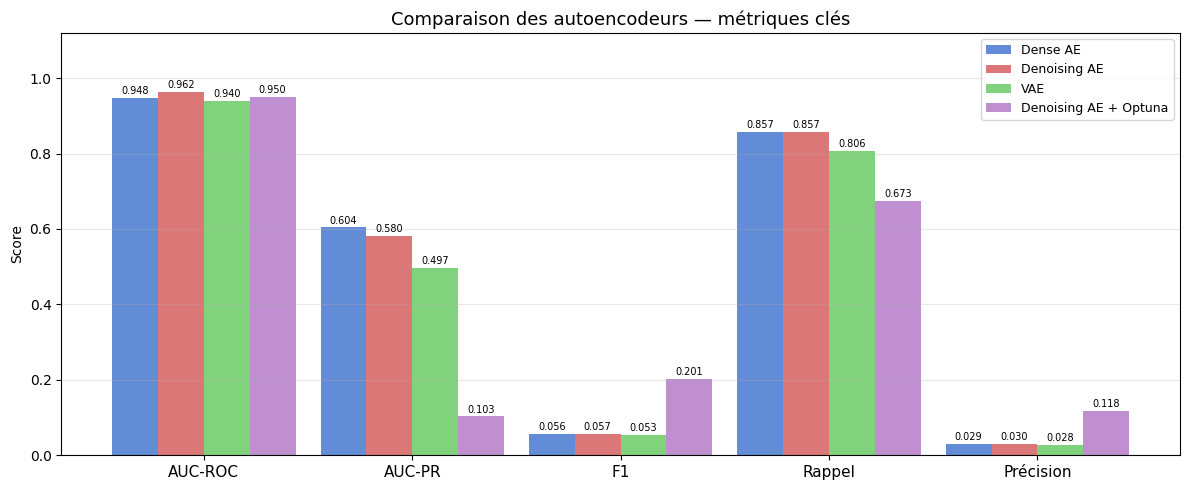

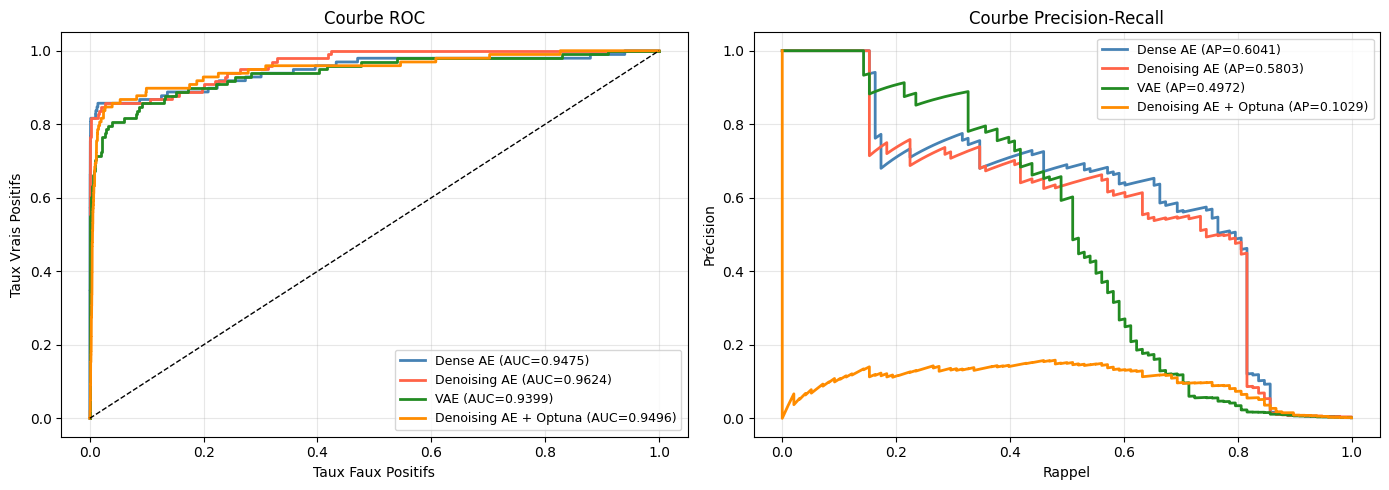

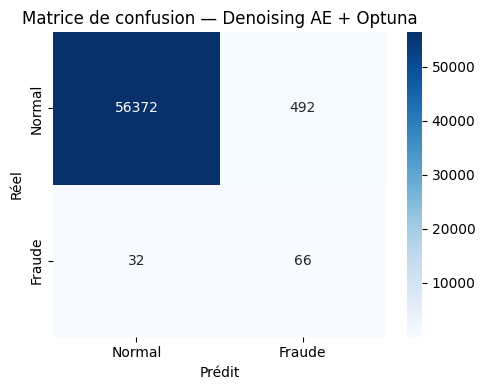


─── Rapport de classification détaillé ───
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00     56864
      Fraude       0.12      0.67      0.20        98

    accuracy                           0.99     56962
   macro avg       0.56      0.83      0.60     56962
weighted avg       1.00      0.99      0.99     56962



In [42]:
# ── Graphiques finaux ──────────────────────────────────────────────────────────
plot_comparison_bar(final_results)
plot_roc_pr_curves(final_results, y_test)

# Matrice de confusion du meilleur modèle final
fig, ax = plt.subplots(figsize=(5, 4))
cm = confusion_matrix(y_test, results_best_optuna['y_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Normal','Fraude'],
            yticklabels=['Normal','Fraude'])
ax.set_title(f"Matrice de confusion — {results_best_optuna['name']}")
ax.set_xlabel('Prédit')
ax.set_ylabel('Réel')
plt.tight_layout()
plt.show()

print("\n─── Rapport de classification détaillé ───")
print(classification_report(y_test, results_best_optuna['y_pred'],
                            target_names=['Normal', 'Fraude'],
                            zero_division=0))